# Edited main figure panels

This notebook assembles the **non-cartoon manuscript panels** for revised Figures 1–5 from the final audited analyses.

## Design rules

- This is a **downstream figure notebook**, not a new work package.
- It does **not retrain any model** and does not redefine the validated geometric analyses.
- Wherever possible it reads the CSV/NPY outputs already written by the audited notebooks.
- The only light recomputations are figure-level transformations: a fixed-seed 2D visualization of the definitive joint CLS embeddings, a canonical-marker summary from the audited aligned counts using the final AE3 state definitions, and Spearman matrices from already-saved residual coordinates/program scores.
- Every panel is saved as **PDF** and **600-dpi PNG**. For large point clouds, points are rasterized inside the PDF while axes/text remain vector.
- The output directory is:
  `revision_audited_mlm/analysis/edited_main_figure_panels/`

Cartoon/schematic panels are intentionally excluded:
- Fig. 1A: dataset + MLM pipeline schematic
- Fig. 2A: projection/residual decomposition schematic


Figure 4B--D use the audited/sample-equal state summaries generated by `Edited_Results_4_malignant_state_programs.ipynb`. Run that notebook first. The user's v4 changes to Figures 2 and 3 are retained.

(*note that in the notebook last running AE was labeled WP, work_package*)

In [ ]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
import scanpy as sc

RANDOM_SEED = 17
rng = np.random.default_rng(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

DATA_ROOT = Path("/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data")
AUDITED_ROOT = DATA_ROOT / "revision_audited_mlm"
MANIFEST_PATH = AUDITED_ROOT / "manifest.json"

AE2 = AUDITED_ROOT / "analysis" / "ae2_clean_joint_seed_17"
AE3 = AUDITED_ROOT / "analysis" / "ae3_developmental_reference_joint_seed_17"
AE5 = AUDITED_ROOT / "analysis" / "ae5_adult_normal_calibration"
AE6 = AUDITED_ROOT / "analysis" / "ae6_representation_dependence_joint_primary"
AE7 = AUDITED_ROOT / "analysis" / "ae7_curved_developmental_manifold"
EDIT1 = AUDITED_ROOT / "analysis" / "edited_results_1_developmental_PC_annotation"
EDIT4 = AUDITED_ROOT / "analysis" / "edited_results_4_malignant_state_programs"

OUTDIR = AUDITED_ROOT / "analysis" / "edited_main_figure_panels"
OUTDIR.mkdir(parents=True, exist_ok=True)

with open(MANIFEST_PATH) as f:
    AUDIT = json.load(f)

DEV_H5AD = Path(AUDIT["dev_h5ad"])
CANCER_H5AD = Path(AUDIT["cancer_h5ad"])
JOINT17 = Path(AUDIT["models"]["joint"]["17"])

def need(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)
    return path

for p in [DEV_H5AD, CANCER_H5AD, JOINT17 / "X_dev_cls.npy",
          JOINT17 / "X_cancer_cls.npy", JOINT17 / "dev_obs_names.npy",
          JOINT17 / "cancer_obs_names.npy"]:
    need(p)

print("Audited root:", AUDITED_ROOT)
print("Figure output:", OUTDIR)
print("Primary joint model:", JOINT17)

Audited root: /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm
Figure output: /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels
Primary joint model: /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/models/joint/seed_17/model


## Shared plotting helpers

The files are deliberately panel-sized for assembly in Keynote.  
PDF is the preferred Keynote input for line/heatmap/bar panels. PNG is useful for point-cloud panels and as a raster fallback.

In [44]:
PNG_DPI = 600

# Shared manuscript heatmap palette.
# The original manuscript program heatmaps used seaborn cmap="vlag".
# Use the actual seaborn colormap object so ax.imshow() reproduces that palette.
HEATMAP_CMAP = sns.color_palette("vlag", as_cmap=True)
PANEL_MANIFEST = []

plt.rcParams.update({
    "font.size": 8,
    "axes.titlesize": 9,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

def save_panel(fig, stem, sources, note="", close=True):
    pdf = OUTDIR / f"{stem}.pdf"
    png = OUTDIR / f"{stem}.png"
    fig.savefig(pdf, bbox_inches="tight")
    fig.savefig(png, dpi=PNG_DPI, bbox_inches="tight")
    PANEL_MANIFEST.append({
        "panel": stem,
        "pdf": str(pdf),
        "png": str(png),
        "sources": " | ".join(map(str, sources)),
        "note": note,
    })
    print("Saved:", pdf.name, "and", png.name)
    if close:
        plt.close(fig)
    return pdf, png

def label_map(s):
    # Readable labels without altering the underlying categorical values.
    return (str(s)
            .replace("_", " ")
            .replace("MPC to ", "MPC → ")
            .replace("MPC_to_", "MPC → ")
            .replace("tip acinar", "tip/acinar"))

def assert_columns(df, cols, name):
    missing = [c for c in cols if c not in df.columns]
    if missing:
        raise KeyError(f"{name}: missing columns {missing}. Present: {list(df.columns)}")

# Figure 1 — developmental reference

### Fig. 1B–C: 2D views of the definitive joint seed-17 CLS representation

A single 2D map is fitted to the **combined developmental + Burdziak CLS embeddings**, so the two displayed panels use the same coordinates.  
UMAP is used if `umap-learn` is available; otherwise the notebook falls back to a two-component PCA. Coordinates are cached to disk for exact reuse.

In [45]:
A_dev = sc.read_h5ad(DEV_H5AD)
A_can = sc.read_h5ad(CANCER_H5AD)

X_dev = np.load(JOINT17 / "X_dev_cls.npy")
X_can = np.load(JOINT17 / "X_cancer_cls.npy")
dev_names = np.load(JOINT17 / "dev_obs_names.npy", allow_pickle=True).astype(str)
can_names = np.load(JOINT17 / "cancer_obs_names.npy", allow_pickle=True).astype(str)

assert np.array_equal(dev_names, A_dev.obs_names.astype(str).to_numpy())
assert np.array_equal(can_names, A_can.obs_names.astype(str).to_numpy())
assert X_dev.shape == (A_dev.n_obs, 256)
assert X_can.shape == (A_can.n_obs, 256)

COORD_CACHE = OUTDIR / "Fig1_BC_joint_seed17_2D_coordinates.csv.gz"

if COORD_CACHE.exists():
    coords_df = pd.read_csv(COORD_CACHE)
    assert len(coords_df) == A_dev.n_obs + A_can.n_obs
    method_2d = coords_df["method"].iloc[0]
    print("Loaded cached 2D coordinates:", method_2d)
else:
    X_all = np.vstack([X_dev, X_can]).astype(np.float32, copy=False)
    p50 = PCA(n_components=min(50, X_all.shape[1]), svd_solver="randomized",
              random_state=RANDOM_SEED)
    X50 = p50.fit_transform(X_all)

    try:
        import umap
        reducer = umap.UMAP(
            n_neighbors=30, min_dist=0.30, metric="cosine",
            n_components=2, random_state=RANDOM_SEED
        )
        Y = reducer.fit_transform(X50)
        method_2d = "UMAP_joint_seed17"
    except Exception as e:
        warnings.warn(
            "umap-learn unavailable or failed; using deterministic PCA2 instead. "
            f"Reason: {e}"
        )
        Y = PCA(n_components=2, random_state=RANDOM_SEED).fit_transform(X50)
        method_2d = "PCA2_joint_seed17"

    coords_df = pd.DataFrame({
        "dataset": (["development"] * A_dev.n_obs) + (["Burdziak"] * A_can.n_obs),
        "cell_id": np.concatenate([dev_names, can_names]),
        "dim1": Y[:, 0],
        "dim2": Y[:, 1],
        "method": method_2d,
    })
    coords_df.to_csv(COORD_CACHE, index=False)
    print("Computed and cached:", method_2d)

dev_xy = coords_df.iloc[:A_dev.n_obs][["dim1", "dim2"]].to_numpy()
can_xy = coords_df.iloc[A_dev.n_obs:][["dim1", "dim2"]].to_numpy()

Loaded cached 2D coordinates: UMAP_joint_seed17


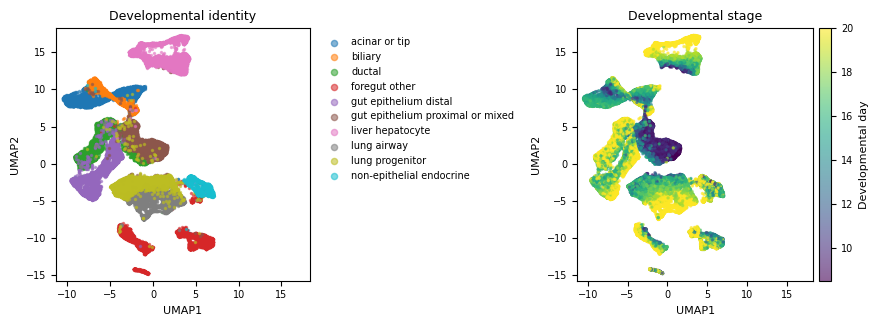

In [ ]:
# Fig. 1B — development: identity and developmental day
dev_identity_col = (
    "dev_state_union"
    if "dev_state_union" in A_dev.obs.columns
    else "celltype_update"
)

# Use the numeric developmental-day variable.  The original `day` column is a
# reporting label and should not be coerced to numeric for this panel.
if "dev_day" not in A_dev.obs.columns:
    raise KeyError(
        "Fig1B requires the numeric `dev_day` column in A_dev.obs."
    )

d = pd.to_numeric(A_dev.obs["dev_day"], errors="coerce").to_numpy()
valid_day = np.isfinite(d)
if valid_day.sum() == 0:
    raise ValueError("Fig1B: `dev_day` contains no finite numeric values.")

# Fig. 1B and Fig. 1C use the SAME 2D coordinate system and the SAME axis limits.
# Limits are defined from the complete combined map, not independently per subset.
all_xy = np.vstack([dev_xy, can_xy])
xmin, xmax = np.nanmin(all_xy[:, 0]), np.nanmax(all_xy[:, 0])
ymin, ymax = np.nanmin(all_xy[:, 1]), np.nanmax(all_xy[:, 1])

xpad = 0.03 * (xmax - xmin) if xmax > xmin else 1.0
ypad = 0.03 * (ymax - ymin) if ymax > ymin else 1.0

FIG1_SHARED_XLIM = (xmin - xpad, xmax + xpad)
FIG1_SHARED_YLIM = (ymin - ypad, ymax + ypad)

fig, axes = plt.subplots(1, 2, figsize=(8.8, 3.3))

# ---- left: developmental identity ----
cats = A_dev.obs[dev_identity_col].astype(str)

pretty_dev_labels = {
    "acinar_or_tip": "acinar or tip",
    "biliary": "biliary",
    "ductal": "ductal",
    "foregut_other": "foregut other",
    "gut_epithelium_distal": "gut epithelium distal",
    "gut_epithelium_proximal_or_mixed": "gut epithelium proximal or mixed",
    "liver_hepatocyte": "liver hepatocyte",
    "lung_airway": "lung airway",
    "lung_progenitor": "lung progenitor",
    "non_epithelial_endocrine": "non-epithelial endocrine",
}

for cat in pd.unique(cats):
    idx = np.flatnonzero(cats.to_numpy() == cat)
    axes[0].scatter(
        dev_xy[idx, 0],
        dev_xy[idx, 1],
        s=2.2,
        alpha=0.55,
        rasterized=True,
        label=pretty_dev_labels.get(cat, label_map(cat)),
    )

axes[0].set_title("Developmental identity")
axes[0].set_xlabel("UMAP1")
axes[0].set_ylabel("UMAP2")
axes[0].set_xlim(FIG1_SHARED_XLIM)
axes[0].set_ylim(FIG1_SHARED_YLIM)
axes[0].legend(
    frameon=False,
    markerscale=3,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    ncol=1,
)

# ---- right: developmental day ----
sca = axes[1].scatter(
    dev_xy[valid_day, 0],
    dev_xy[valid_day, 1],
    c=d[valid_day],
    s=2.2,
    alpha=0.6,
    rasterized=True,
)

cb = fig.colorbar(sca, ax=axes[1], fraction=0.05, pad=0.02)
cb.set_label("Developmental day")

axes[1].set_title("Developmental stage")
axes[1].set_xlabel("UMAP1")
axes[1].set_ylabel("UMAP2")
axes[1].set_xlim(FIG1_SHARED_XLIM)
axes[1].set_ylim(FIG1_SHARED_YLIM)

# No technical suptitle in the manuscript-facing panel.
fig.tight_layout()
plt.show()

save_panel(
    fig,
    "Fig1B_developmental_2D",
    [JOINT17 / "X_dev_cls.npy", DEV_H5AD, COORD_CACHE],
    note=(
        "Developmental cells in the shared combined seed-17 2D map. "
        "Left: dev_state_union identity. Right: numeric dev_day. "
        "Uses the same coordinate limits as Fig1C; point clouds rasterized inside PDF."
    ),
)


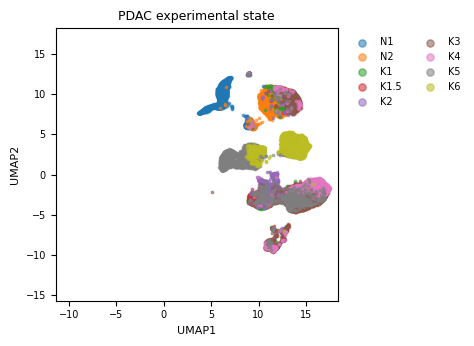

In [ ]:
# Fig. 1C — Burdziak by experimental condition
condition_col = (
    "condition"
    if "condition" in A_can.obs.columns
    else "cancer_state"
)
condition_order = ["N1", "N2", "K1", "K1.5", "K2", "K3", "K4", "K5", "K6"]

# Recompute the shared limits here as well so this cell is safe to run independently.
all_xy = np.vstack([dev_xy, can_xy])
xmin, xmax = np.nanmin(all_xy[:, 0]), np.nanmax(all_xy[:, 0])
ymin, ymax = np.nanmin(all_xy[:, 1]), np.nanmax(all_xy[:, 1])

xpad = 0.03 * (xmax - xmin) if xmax > xmin else 1.0
ypad = 0.03 * (ymax - ymin) if ymax > ymin else 1.0

FIG1_SHARED_XLIM = (xmin - xpad, xmax + xpad)
FIG1_SHARED_YLIM = (ymin - ypad, ymax + ypad)

fig, ax = plt.subplots(figsize=(4.8, 3.5))

cond = A_can.obs[condition_col].astype(str)
ordered = [c for c in condition_order if c in set(cond)]
ordered += [c for c in pd.unique(cond) if c not in ordered]

for c in ordered:
    idx = np.flatnonzero(cond.to_numpy() == c)

    # Display-only downsampling.  The 2D map was already fitted before this step.
    if len(idx) > 3000:
        idx = rng.choice(idx, size=3000, replace=False)

    ax.scatter(
        can_xy[idx, 0],
        can_xy[idx, 1],
        s=3,
        alpha=0.55,
        rasterized=True,
        label=c,
    )

ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
ax.set_title("PDAC experimental state")
ax.set_xlim(FIG1_SHARED_XLIM)
ax.set_ylim(FIG1_SHARED_YLIM)

ax.legend(
    frameon=False,
    markerscale=3,
    ncol=2,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

fig.tight_layout()
plt.show()


save_panel(
    fig,
    "Fig1C_burdziak_2D",
    [JOINT17 / "X_cancer_cls.npy", CANCER_H5AD, COORD_CACHE],
    note=(
        "Burdziak epithelial cells in the same combined seed-17 2D map as Fig1B, "
        "colored by experimental condition. Uses identical coordinate limits; "
        "display-only downsampling to <=3000 cells per condition."
    ),
)


### Fig. 1D: definitive seed-17 developmental PC × program matrix

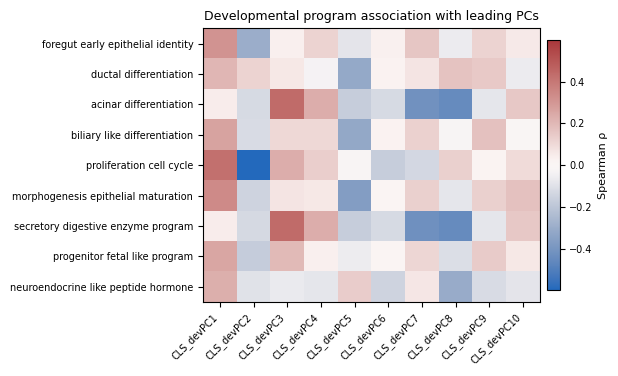

Saved: Fig1D_devPC_programs.pdf and Fig1D_devPC_programs.png


(PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig1D_devPC_programs.pdf'),
 PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig1D_devPC_programs.png'))

In [37]:
matrix_path = need(EDIT1 / "edited_results_1_Fig1B_seed17_devPC_program_matrix.csv")
M = pd.read_csv(matrix_path, index_col=0)

fig, ax = plt.subplots(figsize=(6.2, 3.8))
lim = np.nanmax(np.abs(M.to_numpy()))
im = ax.imshow(M.to_numpy(), aspect="auto", vmin=-lim, vmax=lim, cmap=HEATMAP_CMAP)
ax.set_xticks(np.arange(M.shape[1]))
ax.set_xticklabels([f"CLS_devPC{c}" if str(c).isdigit() else str(c) for c in M.columns],
                   rotation=45, ha="right")
ax.set_yticks(np.arange(M.shape[0]))
ax.set_yticklabels([label_map(x) for x in M.index])
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cb.set_label("Spearman ρ")
ax.set_title("Developmental program association with leading PCs")
fig.tight_layout()
plt.show()

save_panel(fig, "Fig1D_devPC_programs",[matrix_path],note="Definitive Edited_results_1 seed-17 matrix.")

### Fig. 1E: canonical-marker validation of the final WP3 developmental states

This uses the **same final stage/state definitions as WP3** and only summarizes expression for plotting.

In [ ]:
obs = A_dev.obs
ct = obs["celltype_update"].astype(str)
dcol = "dev_day" if "dev_day" in obs.columns else "day"
day = pd.to_numeric(obs[dcol], errors="coerce")

state = pd.Series(pd.NA, index=obs.index, dtype="object")
state[(ct == "Pancreatic acinar cells") & (day <= 11.5)] = "MPC_like"
state[(ct == "Pancreatic acinar cells") & (day >= 13.75) & (day <= 16.5)] = "tip_acinar"
state[(ct == "Pancreatic islets") & (day >= 13.75) & (day <= 16.5)] = "endocrine_secondary"
state[(ct == "Pancreatic islets") & (day >= 16.75)] = "endocrine_late"
state[(ct == "Biliary epithelial cells") & (day >= 11.75) & (day <= 13.5)] = "biliary_early"
state[(ct == "Biliary epithelial cells") & (day >= 13.75) & (day <= 16.5)] = "biliary_secondary"

STATE_ORDER = [
    "MPC_like", "tip_acinar", "endocrine_secondary",
    "endocrine_late", "biliary_early", "biliary_secondary"
]
expected_counts = {
    "MPC_like": 164, "tip_acinar": 2871, "endocrine_secondary": 633,
    "endocrine_late": 556, "biliary_early": 126, "biliary_secondary": 601
}
actual_counts = state.value_counts().to_dict()
for k, v in expected_counts.items():
    assert actual_counts.get(k, 0) == v, (k, actual_counts.get(k, 0), v)

if "symbol" not in A_dev.var.columns:
    raise KeyError("A_dev.var['symbol'] is required for canonical-marker plotting.")
symbol_to_idx = {}
for j, s in enumerate(A_dev.var["symbol"].astype(str)):
    symbol_to_idx.setdefault(s, j)

MARKER_GENES_MAIN = [
    "Pdx1", "Sox9", "Hnf1b", "Nkx6-1", "Ptf1a", "Cpa1",
    "Krt19", "Spp1", "Neurog3", "Neurod1", "Fev", "Chga"
]
missing = [g for g in MARKER_GENES_MAIN if g not in symbol_to_idx]
if missing:
    raise KeyError(f"Missing requested canonical markers: {missing}")

mask = state.notna().to_numpy()
X = A_dev.X
if sparse.issparse(X):
    xmin = X.data.min() if X.nnz else 0.0
else:
    xmin = np.nanmin(X)
assert xmin >= 0, f"A_dev.X contains negative values ({xmin}); do not apply count normalization."

Xsel = X[mask]
lib = np.asarray(Xsel.sum(axis=1)).ravel()
assert np.all(lib > 0)
state_sel = state[mask].astype(str).to_numpy()

rows = []
for gene in MARKER_GENES_MAIN:
    j = symbol_to_idx[gene]
    if sparse.issparse(Xsel):
        raw = np.asarray(Xsel[:, j].toarray()).ravel()
    else:
        raw = np.asarray(Xsel[:, j]).ravel()
    logcpm = np.log1p((raw / lib) * 1e4)
    for st in STATE_ORDER:
        m = state_sel == st
        rows.append({
            "state": st,
            "gene": gene,
            "n_cells": int(m.sum()),
            "mean_log1p_CPM": float(np.mean(logcpm[m])),
            "fraction_detected": float(np.mean(raw[m] > 0)),
        })

marker = pd.DataFrame(rows)
marker.to_csv(OUTDIR / "Fig1E_canonical_marker_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(6.8, 3.3))
plot_marker = marker.copy()
plot_marker["x"] = plot_marker["gene"].map({g:i for i,g in enumerate(MARKER_GENES_MAIN)})
plot_marker["y"] = plot_marker["state"].map({s:i for i,s in enumerate(STATE_ORDER)})
pts = ax.scatter(
    plot_marker["x"], plot_marker["y"],
    s=15 + 260 * plot_marker["fraction_detected"].to_numpy(),
    c=plot_marker["mean_log1p_CPM"].to_numpy()
)
ax.set_xticks(np.arange(len(MARKER_GENES_MAIN)))
ax.set_xticklabels(MARKER_GENES_MAIN, rotation=45, ha="right")
ax.set_yticks(np.arange(len(STATE_ORDER)))
ax.set_yticklabels([label_map(s) for s in STATE_ORDER])
ax.invert_yaxis()
cb = fig.colorbar(pts, ax=ax, fraction=0.035, pad=0.02)
cb.set_label("mean log1p CPM")
ax.set_title("Canonical markers in final Qiu-supported states")
fig.tight_layout()
save_panel(
    fig, "Fig1E_canonical_markers",
    [DEV_H5AD],
    note="Final AE3 state definitions; dot size = detection fraction; expression = mean log1p CPM."
)

Saved: Fig1E_canonical_markers.pdf and Fig1E_canonical_markers.png


(PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig1E_canonical_markers.pdf'),
 PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig1E_canonical_markers.png'))

# Figure 2 — developmental reconstruction and structured residual

### Fig. 2B: primary joint-model projection distributions + biological-sample points + geometric null

The held-out-development control is shown as the distribution of **embryo-level split medians** from AE2; Burdziak conditions retain the cell-level distribution and sample-level medians.

In [ ]:
cell = pd.read_csv(need(AE2 / "cell_metrics_K75.csv"))
sample = pd.read_csv(need(AE2 / "sample_metrics_K75.csv"))
hold = pd.read_csv(need(AE2 / "heldout_development_K75.csv"))
null = pd.read_csv(need(AE2 / "random_subspace_summary_K75.csv"))

assert_columns(cell, ["condition", "projection_fraction"], "AE2 cell metrics")
assert_columns(sample, ["condition", "projection_median"], "AE2 sample metrics")

order = [c for c in ["N1","N2","K1","K1.5","K2","K3","K4","K5","K6"]
         if c in set(cell["condition"].astype(str))]
positions = np.arange(1, len(order) + 1)

fig, ax = plt.subplots(figsize=(7.2, 3.5))

data = [cell.loc[cell["condition"].astype(str).eq(c), "projection_fraction"].dropna().to_numpy()
        for c in order]
ax.violinplot(data, positions=positions, widths=0.75, showmeans=False,
              showmedians=True, showextrema=False)

for x, c in zip(positions, order):
    vals = sample.loc[sample["condition"].astype(str).eq(c), "projection_median"].dropna().to_numpy()
    if len(vals):
        jitter = np.linspace(-0.10, 0.10, len(vals)) if len(vals) > 1 else np.array([0.0])
        ax.scatter(x + jitter, vals, s=22, edgecolor="black", linewidth=0.4, zorder=4)

hvals = hold["heldout_dev_q_median"].dropna().to_numpy()
x0 = 0
jitter = np.linspace(-0.12, 0.12, len(hvals)) if len(hvals) > 1 else np.array([0.0])
ax.scatter(x0 + jitter, hvals, s=22, edgecolor="black", linewidth=0.4, zorder=4)
ax.plot([x0-0.18, x0+0.18], [np.median(hvals)]*2, linewidth=1.5)

nr = null.loc[null["group"].astype(str).eq("all_burdziak")]
if len(nr) == 1:
    r = nr.iloc[0]
    ax.axhspan(r["null_q025"], r["null_q975"], alpha=0.12, label="random 75-D subspace, 95%")
    ax.axhline(r["null_median"], linestyle="--", linewidth=1)

ax.set_xticks(np.arange(0, len(order)+1))
ax.set_xticklabels(["held-out\nDEV"] + order, rotation=45, ha="right")
ax.set_ylabel("developmental projection fraction")
ax.set_ylim(0, 1.03)
#ax.set_title("Primary joint MLM seed 17 (K=75)")
ax.set_title("joint MLM ($k$ = 75)")
ax.legend(frameon=False, loc="lower left")
fig.tight_layout()
save_panel(
    fig, "Fig2B_projection_scores_joint17",
    [AE2 / "cell_metrics_K75.csv", AE2 / "sample_metrics_K75.csv",
     AE2 / "heldout_development_K75.csv", AE2 / "random_subspace_summary_K75.csv"],
    note="Cancer violins are cell-level; points are biological-sample medians. Held-out DEV points are embryo-split medians."
)

Saved: Fig2B_projection_scores_joint17.pdf and Fig2B_projection_scores_joint17.png


(PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig2B_projection_scores_joint17.pdf'),
 PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig2B_projection_scores_joint17.png'))

### Fig. 2extra: independent adult-normal calibration in the development-only seed-17 encoder

In [ ]:
m5 = pd.read_csv(need(AE5 / "ae5_cell_metrics.csv.gz"))
s5 = pd.read_csv(need(AE5 / "ae5_sample_level_summary.csv"))

m5 = m5[m5["encoder"].astype(str).eq("development_only_seed17")].copy()
s5 = s5[s5["encoder"].astype(str).eq("development_only_seed17")].copy()

groups = [
    "heldout_development",
    "adult_acinar", "adult_ductal", "adult_endocrine",
    "N1", "N2", "K1", "K1.5", "K2", "K3", "K4", "K5", "K6"
]
groups = [g for g in groups if g in set(m5["group"].astype(str))]

fig, ax = plt.subplots(figsize=(8.0, 3.5))
pos = np.arange(len(groups))
data = [m5.loc[m5["group"].astype(str).eq(g), "projection_fraction"].dropna().to_numpy()
        for g in groups]
ax.violinplot(data, positions=pos, widths=0.72, showmeans=False,
              showmedians=True, showextrema=False)

for x, g in zip(pos, groups):
    vals = s5.loc[s5["group"].astype(str).eq(g), "projection_median"].dropna().to_numpy()
    if len(vals):
        jitter = np.linspace(-0.11, 0.11, len(vals)) if len(vals) > 1 else np.array([0.0])
        ax.scatter(x + jitter, vals, s=22, edgecolor="black", linewidth=0.4, zorder=4)

ax.set_xticks(pos)
ax.set_xticklabels([label_map(g) for g in groups], rotation=45, ha="right")
ax.set_ylim(0, 1.03)
ax.set_ylabel("developmental projection fraction")
#ax.set_title("Development-only MLM seed 17 — independent adult-normal calibration")
ax.set_title("Development-only MLM — independent adult-normal calibration")
fig.tight_layout()
save_panel(
    fig, "Fig2extra_adult_normal_calibration",
    [AE5 / "ae5_cell_metrics.csv.gz", AE5 / "ae5_sample_level_summary.csv"],
    note="Development-only seed17; violins are cells, points are embryo/mouse/Burdziak-sample medians."
)

/tmp/ipykernel_3624674/3485278351.py:1: DtypeWarning: Columns (14,15,16,17) have mixed types. Specify dtype option on import or set low_memory=False.
  m5 = pd.read_csv(need(WP5 / "wp5_cell_metrics.csv.gz"))


Saved: Fig2extra_adult_normal_calibration.pdf and Fig2extra_adult_normal_calibration.png


(PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig2extra_adult_normal_calibration.pdf'),
 PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig2extra_adult_normal_calibration.png'))

### Fig. 2C: residual PC1/PC2 after fitting residual PCA on K1–K6 only

In [ ]:
res = pd.read_csv(need(AE2 / "tumor_defined_residual_scores_K75.csv"), index_col=0)
assert_columns(res, ["condition", "TumorResPC1", "TumorResPC2"], "AE2 residual scores")

fig, ax = plt.subplots(figsize=(4.8, 3.7))
cond = res["condition"].astype(str)
order = [c for c in ["N1","N2","K1","K1.5","K2","K3","K4","K5","K6"] if c in set(cond)]

for c in order:
    idx = np.flatnonzero(cond.to_numpy() == c)
    if len(idx) > 1500:
        idx = rng.choice(idx, size=1500, replace=False)
    ax.scatter(res.iloc[idx]["TumorResPC1"], res.iloc[idx]["TumorResPC2"],
               s=4, alpha=0.45, rasterized=True, label=c)

ax.set_xlabel("K-series-defined residual PC1")
ax.set_ylabel("K-series-defined residual PC2")
ax.set_title("Residual PCA fitted on K1–K6 only")
ax.legend(frameon=False, ncol=2, markerscale=2.5, bbox_to_anchor=(1.02, 1),
          loc="upper left")
fig.tight_layout()
save_panel(
    fig, "Fig2C_Kseries_residual_PC1_PC2",
    [AE2 / "tumor_defined_residual_scores_K75.csv"],
    note="N1/N2 are projected references and do not define residual PCA axes."
)

Saved: Fig2C_Kseries_residual_PC1_PC2.pdf and Fig2C_Kseries_residual_PC1_PC2.png


(PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig2C_Kseries_residual_PC1_PC2.pdf'),
 PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig2C_Kseries_residual_PC1_PC2.png'))

### Fig. 2D: transcriptional programs associated with the K-series-defined residual axes

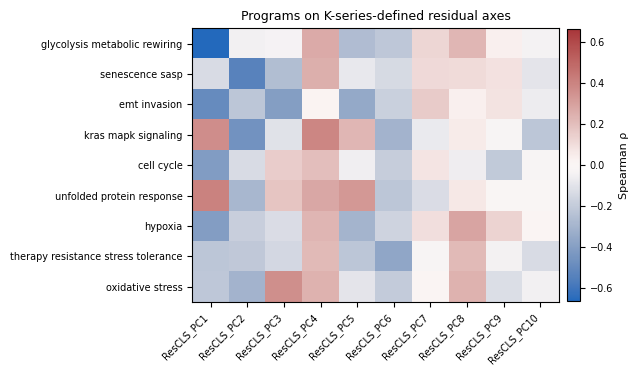

Saved: Fig2D_Kseries_residual_programs.pdf and Fig2D_Kseries_residual_programs.png


(PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig2D_Kseries_residual_programs.pdf'),
 PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig2D_Kseries_residual_programs.png'))

In [ ]:
res = pd.read_csv(need(AE2 / "tumor_defined_residual_scores_K75.csv"), index_col=0)
prog = pd.read_csv(need(AE2 / "cancer_program_scores_log1pCPM.csv"), index_col=0)

common = res.index.intersection(prog.index)
if len(common) < 100:
    if len(res) != len(prog):
        raise ValueError("Residual/program score tables do not align by index or length.")
    warnings.warn("Using audited row order because cell IDs did not intersect cleanly.")
    prog = prog.copy()
    prog.index = res.index
    common = res.index

R = res.loc[common]
P = prog.loc[common]
k_mask = R["condition"].astype(str).str.startswith("K").to_numpy()
pc_cols = [c for c in R.columns if c.startswith("TumorResPC")][:10]

key_programs = [
    "glycolysis_metabolic_rewiring", "senescence_sasp", "emt_invasion",
    "kras_mapk_signaling", "cell_cycle", "unfolded_protein_response",
    "hypoxia", "therapy_resistance_stress_tolerance", "oxidative_stress"
]
key_programs = [p for p in key_programs if p in P.columns]

mat = np.full((len(key_programs), len(pc_cols)), np.nan)
for i, pname in enumerate(key_programs):
    y = P[pname].to_numpy()[k_mask]
    for j, pc in enumerate(pc_cols):
        x = R[pc].to_numpy()[k_mask]
        mat[i, j] = spearmanr(x, y, nan_policy="omit").correlation

corr = pd.DataFrame(mat, index=key_programs, columns=pc_cols)
corr.to_csv(OUTDIR / "Fig2D_Kseries_residual_program_correlations.csv")

fig, ax = plt.subplots(figsize=(6.4, 3.8))

# Explicit manuscript heatmap palette
vlag_cmap = sns.color_palette("vlag", as_cmap=True)

lim = np.nanmax(np.abs(mat))

im = ax.imshow(
    mat,
    aspect="auto",
    vmin=-lim,
    vmax=lim,
    cmap=vlag_cmap
)

ax.set_xticks(np.arange(len(pc_cols)))
ax.set_xticklabels(
    [c.replace("TumorResPC", "ResCLS_PC") for c in pc_cols],
    rotation=45,
    ha="right"
)

ax.set_yticks(np.arange(len(key_programs)))
ax.set_yticklabels([label_map(p) for p in key_programs])

cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cb.set_label("Spearman ρ")

ax.set_title("Programs on K-series-defined residual axes")

fig.tight_layout()

plt.show()
save_panel(
    fig,
    "Fig2D_Kseries_residual_programs",
    [
        AE2 / "tumor_defined_residual_scores_K75.csv",
        AE2 / "cancer_program_scores_log1pCPM.csv",
    ],
    note=(
        "Spearman correlations evaluated on K-series cells only; "
        "seaborn vlag diverging palette centered at zero."
    ),
)


# Figure 3 — malignant-state differences versus developmental directions

### Fig. 3A: final AE3 sample-level bootstrap estimates

In [ ]:
boot = pd.read_csv(need(AE3 / "ae3_revised_direction_sample_bootstrap.csv"))
point = pd.read_csv(need(AE3 / "ae3_revised_direction_sample_equal_point_estimates.csv"))
null3 = pd.read_csv(need(AE3 / "ae3_revised_direction_random_null.csv"))
assert_columns(boot, ["transition", "developmental_direction", "median", "lo", "hi"], "AE3 bootstrap")
assert "transition" in point.columns

dir_order = [
    "MPC_to_tip_acinar", "MPC_to_endocrine_islet",
    "endocrine_maturation", "biliary_maturation"
]
dir_order = [d for d in dir_order if d in set(boot["developmental_direction"])]
transitions = ["early", "late", "total"]
offsets = dict(zip(transitions, [-0.18, 0.0, 0.18]))

# Convert the observed sample-equal point estimates from wide to long.
point_long = point.melt(
    id_vars=["transition"],
    value_vars=[d for d in dir_order if d in point.columns],
    var_name="developmental_direction",
    value_name="observed_cosine",
)

fig, ax = plt.subplots(figsize=(6.0, 3.8))
ybase = np.arange(len(dir_order))

for t in transitions:
    b = boot[boot["transition"].astype(str).eq(t)].set_index("developmental_direction").reindex(dir_order)
    p = point_long[point_long["transition"].astype(str).eq(t)].set_index("developmental_direction").reindex(dir_order)
    y = ybase + offsets[t]
    x = p["observed_cosine"].to_numpy(dtype=float)
    xerr = np.vstack([x - b["lo"].to_numpy(), b["hi"].to_numpy() - x])
    # If the observed point falls just outside a bootstrap percentile bound, clip only the
    # graphical error length at zero; the CSV values are not altered.
    xerr = np.maximum(xerr, 0)
    ax.errorbar(x, y, xerr=xerr, fmt="o", capsize=2, label=t)

ax.axvline(0, linewidth=0.8)
ax.set_yticks(ybase)
ax.set_yticklabels([label_map(d) for d in dir_order])
ax.set_xlabel("cosine similarity")
ax.set_title("Sample-balanced malignant displacements vs developmental directions")
ax.legend(frameon=False, title="displacement")

if {"transition", "upper_tail_empirical_p"}.issubset(null3.columns):
    ptxt = "; ".join(
        f"{r.transition} p={r.upper_tail_empirical_p:.3g}"
        for r in null3.itertuples()
    )
    ax.text(0.01, -0.20, "max-|cosine| random-direction test: " + ptxt,
            transform=ax.transAxes, fontsize=6.5)

fig.tight_layout()
save_panel(
    fig, "Fig3A_developmental_direction_cosines",
    [AE3 / "ae3_revised_direction_sample_equal_point_estimates.csv",
     AE3 / "ae3_revised_direction_sample_bootstrap.csv",
     AE3 / "ae3_revised_direction_random_null.csv"],
    note="Points are observed biological-sample-equal estimates; intervals are biological-sample bootstrap; null p-values use max absolute cosine."
)

Saved: Fig3A_developmental_direction_cosines.pdf and Fig3A_developmental_direction_cosines.png


(PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig3A_developmental_direction_cosines.pdf'),
 PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig3A_developmental_direction_cosines.png'))

### Fig. 3B: robustness of the reverse MPC→tip/acinar result across representations

In [ ]:
m6 = pd.read_csv(
    need(AE6 / "ae6_matched_variance_direction_cosines.csv")
)

assert_columns(
    m6,
    [
        "variance_target",
        "representation",
        "transition",
        "developmental_direction",
        "cosine",
        "centroid_weighting",
    ],
    "AE6 matched directions",
)

# Manuscript-primary AE3/AE6 developmental construction:
# equal weight to each represented developmental day.
s = m6[
    m6["variance_target"].astype(str).eq("95pct")
    & m6["centroid_weighting"].astype(str).eq("equal_day")
    & m6["developmental_direction"].astype(str).eq("MPC_to_tip_acinar")
    & m6["transition"].astype(str).isin(["early", "total"])
].copy()

rep_order = [
    "joint_MLM",
    "joint_expression_PCA",
    "joint_scVI_seed17",
    "joint_scVI_seed42",
]
rep_order = [r for r in rep_order if r in set(s["representation"])]
trans_order = ["early", "total"]

# Fail rather than silently average if the biological specification is not unique.
dup = s.duplicated(
    subset=["representation", "transition"],
    keep=False,
)
if dup.any():
    display(
        s.loc[
            dup,
            [
                "representation",
                "transition",
                "centroid_weighting",
                "developmental_direction",
                "cosine",
            ],
        ].sort_values(["transition", "representation"])
    )
    raise ValueError(
        "Fig3C still has duplicate representation × transition rows."
    )

fig, ax = plt.subplots(figsize=(5.4, 3.2))
x = np.arange(len(rep_order))

for i, t in enumerate(trans_order):
    ss = (
        s[s["transition"].astype(str).eq(t)]
        .set_index("representation")
        .reindex(rep_order)
    )

    ax.scatter(
        x + (i - 0.5) * 0.16,
        ss["cosine"],
        s=35,
        label=t,
    )

ax.axhline(0, linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(
    [label_map(r).replace("joint ", "") for r in rep_order],
    rotation=35,
    ha="right",
)
ax.set_ylabel("MPC → tip/acinar cosine")
ax.set_title("Matched 95% developmental variance")
ax.legend(frameon=False)

fig.tight_layout()

save_panel(
    fig,
    "Fig3B_representation_robustness",
    [AE6 / "ae6_matched_variance_direction_cosines.csv"],
    note=(
        "Early and total malignant displacements; matched 95% developmental variance; "
        "equal-day developmental centroid weighting."
    ),
)


Saved: Fig3B_representation_robustness.pdf and Fig3B_representation_robustness.png


(PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig3B_representation_robustness.pdf'),
 PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig3B_representation_robustness.png'))


# Figure 4 — malignant-state position and biological identity

Figure 4 combines the final AE3 positional comparison with sample-equal state summaries rebuilt in `Edited_Results_4_malignant_state_programs.ipynb`.

- **A:** distance of each malignant-state centroid to the final AE3 developmental reference states;
- **B:** developmental-program enrichment by malignant state;
- **C:** selected cancer-program enrichment by malignant state (the complete matrix is retained in Edited Results 4 for Supplement);
- **D:** enrichment of the final K1–K6-defined residual PCs by malignant state.

Panels B--D use the same rule: scores are z-scored across Burdziak cells, averaged within each `cancer_state × batch`, and then averaged equally across sample labels within state.


### Fig. 4A: distances from malignant-state centroids to the final AE3 developmental states

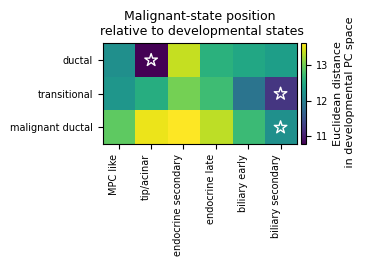

Saved: Fig4A_malignant_developmental_distances.pdf and Fig4A_malignant_developmental_distances.png


(PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig4A_malignant_developmental_distances.pdf'),
 PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig4A_malignant_developmental_distances.png'))

In [ ]:

dist = pd.read_csv(need(AE3 / "ae3_cancer_to_development_centroid_distances.csv"), index_col=0)

state_order = ["ductal", "transitional", "malignant_ductal"]
dev_order = [
    "MPC_like", "tip_acinar", "endocrine_secondary", "endocrine_late",
    "biliary_early", "biliary_secondary"
]
state_order = [s for s in state_order if s in dist.index]
dev_order = [s for s in dev_order if s in dist.columns]
dist = dist.reindex(index=state_order, columns=dev_order)

fig, ax = plt.subplots(figsize=(3.8, 2.7))
# Distances are non-negative, so use a sequential palette rather than the zero-centered vlag palette.
im = ax.imshow(dist.to_numpy(), aspect="auto", cmap="viridis")
ax.set_xticks(np.arange(dist.shape[1]))
ax.set_xticklabels([label_map(c) for c in dist.columns], rotation=90, ha="right")
ax.set_yticks(np.arange(dist.shape[0]))
ax.set_yticklabels([label_map(i) for i in dist.index])

nearest = np.argmin(dist.to_numpy(), axis=1)
for i, j in enumerate(nearest):
    ax.scatter(j, i, marker="*", s=90, facecolors="none", edgecolors="white", linewidth=1.0)

cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cb.set_label("Euclidean distance\n in developmental PC space")
ax.set_title("Malignant-state position\n relative to developmental states")
fig.tight_layout()
plt.show()

save_panel(
    fig, "Fig4A_malignant_developmental_distances",
    [AE3 / "ae3_cancer_to_development_centroid_distances.csv"],
    note="Stars mark the nearest developmental centroid among the final AE3 states present in the audited distance table."
)


### Fig. 4B: developmental-program enrichment by malignant state

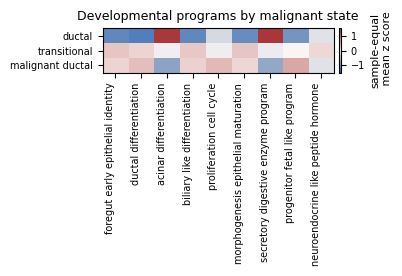

Saved: Fig4B_state_developmental_programs.pdf and Fig4B_state_developmental_programs.png


(PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig4B_state_developmental_programs.pdf'),
 PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig4B_state_developmental_programs.png'))

In [49]:
M = pd.read_csv(need(EDIT4 / "edited_results_4_state_developmental_program_zmeans_sample_equal.csv"),index_col=0)
state_order = [s for s in ["ductal", "transitional", "malignant_ductal"] if s in M.index]
M = M.reindex(state_order)

fig, ax = plt.subplots(figsize=(4.2, 2.8))
lim = np.nanmax(np.abs(M.to_numpy()))
im = ax.imshow(M.to_numpy(), aspect="auto", vmin=-lim, vmax=lim, cmap=HEATMAP_CMAP)
ax.set_xticks(np.arange(M.shape[1]))
ax.set_xticklabels([label_map(c) for c in M.columns], rotation=90, ha="right")
ax.set_yticks(np.arange(M.shape[0]))
ax.set_yticklabels([label_map(i) for i in M.index])
cb = fig.colorbar(im, ax=ax, fraction=0.05, pad=0.02)
cb.set_label("sample-equal\n mean z score")
ax.set_title("Developmental programs by malignant state")
fig.tight_layout()
plt.show()
save_panel(
    fig, "Fig4B_state_developmental_programs",
    [EDIT4 / "edited_results_4_state_developmental_program_zmeans_sample_equal.csv"],
    note="Cell-level program scores z-scored across Burdziak cells; sample means computed within state and averaged equally across sample labels."
)


### Fig. 4C: cancer-program enrichment by malignant state

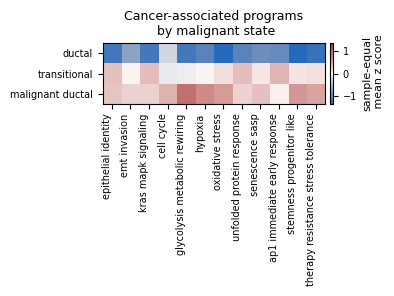

Saved: Fig4C_state_cancer_programs.pdf and Fig4C_state_cancer_programs.png


(PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig4C_state_cancer_programs.pdf'),
 PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig4C_state_cancer_programs.png'))

In [50]:

M = pd.read_csv(
    need(EDIT4 / "edited_results_4_state_cancer_program_zmeans_sample_equal_main.csv"),
    index_col=0,
)
state_order = [s for s in ["ductal", "transitional", "malignant_ductal"] if s in M.index]
M = M.reindex(state_order)

fig, ax = plt.subplots(figsize=(4.1, 3.))
lim = np.nanmax(np.abs(M.to_numpy()))
im = ax.imshow(M.to_numpy(), aspect="auto", vmin=-lim, vmax=lim, cmap=HEATMAP_CMAP)
ax.set_xticks(np.arange(M.shape[1]))
ax.set_xticklabels([label_map(c) for c in M.columns], rotation=90, ha="right")
ax.set_yticks(np.arange(M.shape[0]))
ax.set_yticklabels([label_map(i) for i in M.index])
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cb.set_label("sample-equal\n mean z score")
ax.set_title("Cancer-associated programs\n by malignant state")
fig.tight_layout()
plt.show()

save_panel(
    fig, "Fig4C_state_cancer_programs",
    [EDIT4 / "edited_results_4_state_cancer_program_zmeans_sample_equal_main.csv"],
    note="Pre-specified compact program subset for the main figure; the full audited sample-equal matrix is written by Edited Results 4."
)


### Fig. 4D: K-series-defined residual-axis enrichment by malignant state

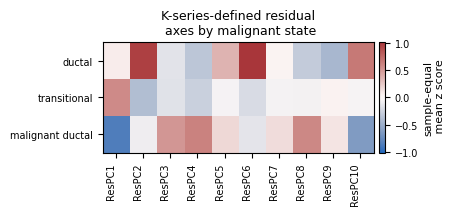

Saved: Fig4D_state_residual_axes.pdf and Fig4D_state_residual_axes.png


(PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig4D_state_residual_axes.pdf'),
 PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig4D_state_residual_axes.png'))

In [ ]:
M = pd.read_csv(need(EDIT4 / "edited_results_4_state_residual_pc_zmeans_sample_equal.csv"),index_col=0)
state_order = [s for s in ["ductal", "transitional", "malignant_ductal"] if s in M.index]
M = M.reindex(state_order)
M.columns = [c.replace("TumorResPC", "ResPC") for c in M.columns]

fig, ax = plt.subplots(figsize=(4.6, 2.2))
lim = np.nanmax(np.abs(M.to_numpy()))
im = ax.imshow(M.to_numpy(), aspect="auto", vmin=-lim, vmax=lim, cmap=HEATMAP_CMAP)
ax.set_xticks(np.arange(M.shape[1]))
ax.set_xticklabels(M.columns, rotation=90, ha="right")
ax.set_yticks(np.arange(M.shape[0]))
ax.set_yticklabels([label_map(i) for i in M.index])
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cb.set_label("sample-equal\n mean z score")
ax.set_title("K-series-defined residual\n axes by malignant state")
fig.tight_layout()
plt.show()

save_panel(
    fig, "Fig4D_state_residual_axes",
    [EDIT4 / "edited_results_4_state_residual_pc_zmeans_sample_equal.csv",
     AE2 / "tumor_defined_residual_scores_K75.csv"],
    note="Residual PCA axes were fitted on K1–K6 only in AE2; this panel only summarizes their state enrichment with sample-equal weighting."
)


### Fig. 4 extra: adult-normal nearest developmental identity (retain for Supplement if useful)

In [ ]:
adult = pd.read_csv(need(AE5 / "ae5_adult_nearest_identity_long.csv"))
adult = adult[adult["encoder"].astype(str).eq("development_only_seed17")].copy()
if "domain_assumption" in adult.columns:
    adult = adult[adult["domain_assumption"].astype(str).isin(["DEV", "NONE"])]

assert_columns(adult, ["subgroup", "nearest_dev_identity", "n_cells"], "AE5 adult nearest identity")

tab = adult.pivot_table(index="subgroup", columns="nearest_dev_identity",
                        values="n_cells", aggfunc="sum", fill_value=0)
tab = tab.div(tab.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(6.0, 3.1))
bottom = np.zeros(len(tab))
x = np.arange(len(tab))
for col in tab.columns:
    vals = tab[col].to_numpy()
    ax.bar(x, vals, bottom=bottom, label=label_map(col))
    bottom += vals

ax.set_xticks(x)
ax.set_xticklabels([label_map(i) for i in tab.index])
ax.set_ylim(0, 1)
ax.set_ylabel("fraction of adult cells")
ax.set_title("Nearest developmental identity — adult-normal pancreas")
ax.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
save_panel(
    fig, "Fig4extra_adult_nearest_developmental_identity",
    [AE5 / "ae5_adult_nearest_identity_long.csv"],
    note="Frozen development-only MLM seed17."
)

Saved: Fig4extra_adult_nearest_developmental_identity.pdf and Fig4extra_adult_nearest_developmental_identity.png


(PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig4extra_adult_nearest_developmental_identity.pdf'),
 PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig4extra_adult_nearest_developmental_identity.png'))

# Figure 5 — local developmental manifold control

### Fig. 5A: local-manifold calibration

In [ ]:
cal = pd.read_csv(need(AE7 / "ae7_primary_devonly_local_calibration_summary.csv"))
assert_columns(cal, ["seed", "group", "median_local_projection_fraction"], "AE7 calibration")

group_order = [
    "heldout_development", "adult_acinar", "adult_ductal", "adult_endocrine",
    "Burdziak_N1", "Burdziak_N2", "K_series_all", "overt_K5_K6"
]
group_order = [g for g in group_order if g in set(cal["group"])]

fig, ax = plt.subplots(figsize=(6.8, 3.3))
x = np.arange(len(group_order))
for off, seed in zip([-0.08, 0.08], sorted(cal["seed"].unique())):
    s = cal[cal["seed"].eq(seed)].set_index("group").reindex(group_order)
    ax.scatter(x + off, s["median_local_projection_fraction"], s=34, label=f"seed {seed}")
    if {"q25_local_projection_fraction","q75_local_projection_fraction"}.issubset(s.columns):
        med = s["median_local_projection_fraction"].to_numpy()
        err = np.vstack([
            med - s["q25_local_projection_fraction"].to_numpy(),
            s["q75_local_projection_fraction"].to_numpy() - med
        ])
        ax.errorbar(x + off, med, yerr=err, fmt="none", capsize=2, linewidth=0.8)

ax.set_xticks(x)
ax.set_xticklabels([label_map(g) for g in group_order], rotation=35, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("local projection fraction")
ax.set_title("Local developmental-manifold calibration")
ax.legend(frameon=False)
fig.tight_layout()
save_panel(
    fig, "Fig5A_local_manifold_calibration",
    [AE7 / "ae7_primary_devonly_local_calibration_summary.csv"],
    note="Development-only MLM seeds 17 and 42; local k=50, tangent q=10."
)

Saved: Fig5A_local_manifold_calibration.pdf and Fig5A_local_manifold_calibration.png


(PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig5A_local_manifold_calibration.pdf'),
 PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig5A_local_manifold_calibration.png'))

### Fig. 5B: malignant displacement captured by local developmental tangents

In [ ]:
tan = pd.read_csv(need(AE7 / "ae7_primary_devonly_tangent_capture_summary.csv"))
nul = pd.read_csv(need(AE7 / "ae7_primary_devonly_tangent_random_subspace_null.csv"))

trans = ["early", "late", "total"]
fig, ax = plt.subplots(figsize=(4.7, 3.2))
x = np.arange(len(trans))
for off, seed in zip([-0.08, 0.08], sorted(tan["seed"].unique())):
    s = tan[tan["seed"].eq(seed)].set_index("transition").reindex(trans)
    ax.scatter(x + off, s["sample_equal_median_tangent_fraction"], s=38, label=f"seed {seed}")
    if {"q25_sample_medians","q75_sample_medians"}.issubset(s.columns):
        med = s["sample_equal_median_tangent_fraction"].to_numpy()
        err = np.vstack([
            med - s["q25_sample_medians"].to_numpy(),
            s["q75_sample_medians"].to_numpy() - med
        ])
        ax.errorbar(x + off, med, yerr=err, fmt="none", capsize=2, linewidth=0.8)

random_mean = float(nul["random_mean"].iloc[0])
random_lo = float(nul["random_q025"].iloc[0])
random_hi = float(nul["random_q975"].iloc[0])
ax.axhspan(random_lo, random_hi, alpha=0.12)
ax.axhline(random_mean, linestyle="--", linewidth=1, label="random q/D")

ax.set_xticks(x)
ax.set_xticklabels(trans)
ax.set_ylim(0, 0.8)
ax.set_ylabel("sample-equal median tangent capture")
ax.set_title("Malignant displacement within local developmental tangents")
ax.legend(frameon=False)
fig.tight_layout()
save_panel(
    fig, "Fig5B_local_tangent_capture",
    [AE7 / "ae7_primary_devonly_tangent_capture_summary.csv",
     AE7 / "ae7_primary_devonly_tangent_random_subspace_null.csv"],
    note="Development-only seeds; random q=10 in D=256 benchmark shown as band/line."
)

Saved: Fig5B_local_tangent_capture.pdf and Fig5B_local_tangent_capture.png


(PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig5B_local_tangent_capture.pdf'),
 PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig5B_local_tangent_capture.png'))

### Fig. 5C: representation dependence of local tangent capture

In [ ]:
devonly = pd.read_csv(need(AE7 / "ae7_primary_devonly_tangent_capture_summary.csv"))
joint = pd.read_csv(need(AE7 / "ae7_secondary_joint_tangent_capture_summary.csv"))

dev17 = devonly[devonly["seed"].eq(17)][
    ["transition", "sample_equal_median_tangent_fraction"]
].copy()
dev17["representation"] = "development-only MLM seed17"

joint_value_col = (
    "sample_equal_median_tangent_fraction"
    if "sample_equal_median_tangent_fraction" in joint.columns
    else "median_tangent_fraction"
)
j = joint[["transition", joint_value_col]].copy()
j = j.rename(columns={joint_value_col: "sample_equal_median_tangent_fraction"})
j["representation"] = "joint MLM seed17"

cmp = pd.concat([dev17, j], ignore_index=True)
trans = ["early", "late", "total"]
reps = ["development-only MLM seed17", "joint MLM seed17"]

fig, ax = plt.subplots(figsize=(4.8, 3.2))
x = np.arange(len(trans))
for i, rep in enumerate(reps):
    s = cmp[cmp["representation"].eq(rep)].set_index("transition").reindex(trans)
    ax.scatter(x + (i - 0.5)*0.16, s["sample_equal_median_tangent_fraction"],
               s=42, label=rep)

ax.set_xticks(x)
ax.set_xticklabels(trans)
ax.set_ylim(0, 0.65)
ax.set_ylabel("median tangent capture")
ax.set_title("Local developmental compatibility depends on representation")
ax.legend(frameon=False)
fig.tight_layout()
save_panel(
    fig, "Fig5C_joint_vs_devonly_tangent_capture",
    [AE7 / "ae7_primary_devonly_tangent_capture_summary.csv",
     AE7 / "ae7_secondary_joint_tangent_capture_summary.csv"],
    note="Seed17 development-only versus seed17 joint MLM."
)

Saved: Fig5C_joint_vs_devonly_tangent_capture.pdf and Fig5C_joint_vs_devonly_tangent_capture.png


(PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig5C_joint_vs_devonly_tangent_capture.pdf'),
 PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig5C_joint_vs_devonly_tangent_capture.png'))

### Fig. 5D: biological composition of the local developmental neighborhoods

In [ ]:
comp = pd.read_csv(need(AE7 / "ae7_primary_local_tangent_ae3_composition.csv"))
comp = comp[comp["seed"].eq(17)].copy()
assert_columns(comp, ["transition", "ae3_state", "equal_sample_mean_neighbor_fraction"],
               "AE7 tangent composition")

trans = ["early", "late", "total"]
state_order = [
    "MPC_like", "tip_acinar", "endocrine_secondary", "endocrine_late",
    "biliary_early", "biliary_secondary", "other_development"
]
state_order = [s for s in state_order if s in set(comp["ae3_state"])]

tab = comp.pivot_table(index="transition", columns="ae3_state",
                       values="equal_sample_mean_neighbor_fraction",
                       aggfunc="first", fill_value=0).reindex(trans)
tab = tab.reindex(columns=state_order, fill_value=0)

fig, ax = plt.subplots(figsize=(5.5, 3.2))
x = np.arange(len(tab))
bottom = np.zeros(len(tab))
for col in tab.columns:
    vals = tab[col].to_numpy()
    ax.bar(x, vals, bottom=bottom, label=label_map(col))
    bottom += vals

ax.set_xticks(x)
ax.set_xticklabels(tab.index)
ax.set_ylim(0, 1)
ax.set_ylabel("mean neighborhood fraction")
#ax.set_title("Developmental composition of local tangents — seed 17")
ax.set_title("Developmental composition of local tangents")
ax.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
save_panel(
    fig, "Fig5D_local_tangent_composition",
    [AE7 / "ae7_primary_local_tangent_ae3_composition.csv"],
    note="Equal-sample mean neighborhood composition in final AE3 state labels."
)

Saved: Fig5D_local_tangent_composition.pdf and Fig5D_local_tangent_composition.png


(PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig5D_local_tangent_composition.pdf'),
 PosixPath('/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/Fig5D_local_tangent_composition.png'))

# Final audit and panel/source manifest

This cell checks every manuscript-facing non-cartoon panel and writes a machine-readable source table.

In [23]:
MAIN_PANEL_STEMS = [
    "Fig1B_developmental_2D",
    "Fig1C_burdziak_2D",
    "Fig1D_devPC_programs",
    "Fig1E_canonical_markers",
    "Fig2B_projection_scores_joint17",
    "Fig2C_Kseries_residual_PC1_PC2",
    "Fig2D_Kseries_residual_programs",
    "Fig3A_developmental_direction_cosines",
    "Fig3B_representation_robustness",
    "Fig4A_malignant_developmental_distances",
    "Fig4B_state_developmental_programs",
    "Fig4C_state_cancer_programs",
    "Fig4D_state_residual_axes",
    "Fig5A_local_manifold_calibration",
    "Fig5B_local_tangent_capture",
    "Fig5C_joint_vs_devonly_tangent_capture",
    "Fig5D_local_tangent_composition",
]

missing = []
for stem in MAIN_PANEL_STEMS:
    for ext in ["pdf", "png"]:
        p = OUTDIR / f"{stem}.{ext}"
        if not p.exists():
            missing.append(str(p))
if missing:
    raise FileNotFoundError("Missing expected manuscript panel outputs:\n" + "\n".join(missing))

manifest_df = pd.DataFrame(PANEL_MANIFEST)
manifest_df.to_csv(OUTDIR / "edited_main_figure_panel_manifest.csv", index=False)

panel_audit = {
    "status": "PASS",
    "main_panel_stems": MAIN_PANEL_STEMS,
    "figure4_recomputation_source": str(EDIT4),
    "panel_manifest_rows_this_run": len(PANEL_MANIFEST),
    "note": "Figure 4B-D use Edited Results 4 sample-equal summaries. Fig4extra adult-normal calibration is optional and not required for the main figure audit.",
}
with open(OUTDIR / "edited_main_figure_panel_audit.json", "w") as f:
    json.dump(panel_audit, f, indent=2)

print("EDITED MAIN FIGURE PANEL AUDIT STATUS: PASS")
print("Manifest:", OUTDIR / "edited_main_figure_panel_manifest.csv")


EDITED MAIN FIGURE PANEL AUDIT STATUS: PASS
Manifest: /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/edited_main_figure_panels/edited_main_figure_panel_manifest.csv
